In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_curve, auc)
import seaborn as sns

In [3]:
model = tf.keras.models.load_model("../outputs/models/best_model.keras")

test_datagen = ImageDataGenerator(rescale=1./255)

test_gen = test_datagen.flow_from_directory(
    "../data/test",
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    shuffle=False  
)

class_names = list(test_gen.class_indices.keys())  
print("Classes:", class_names)

Found 600 images belonging to 2 classes.
Classes: ['cat', 'dog']


In [4]:
y_pred_prob = model.predict(test_gen, verbose=1)   
y_pred      = (y_pred_prob > 0.5).astype(int).flatten() 
y_true      = test_gen.classes           

print(f"\nจำนวนรูปที่ทดสอบ : {len(y_true)}")
print(f"Predict ถูก       : {(y_pred == y_true).sum()}")
print(f"Predict ผิด       : {(y_pred != y_true).sum()}")

19/19 ━━━━━━━━━━━━━━━━━━━━ 10s 474ms/step

จำนวนรูปที่ทดสอบ : 600
Predict ถูก       : 591
Predict ผิด       : 9


In [5]:
print(classification_report(y_true, y_pred, target_names=class_names))

              precision    recall  f1-score   support

         cat       1.00      0.97      0.98       300
         dog       0.97      1.00      0.99       300

    accuracy                           0.98       600
   macro avg       0.99      0.99      0.98       600
weighted avg       0.99      0.98      0.98       600



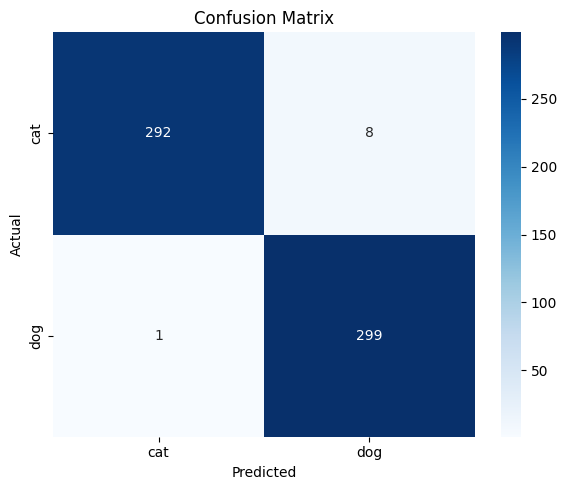

finish


In [6]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.savefig("../outputs/plots/confusion_matrix.png")
plt.show()
print("finish")

# อ่าน Confusion Matrix:
# แถวคือ label จริง, คอลัมน์คือที่โมเดลทาย
# diagonal (แนวทแยง) = ทายถูก
# นอก diagonal = ทายผิด

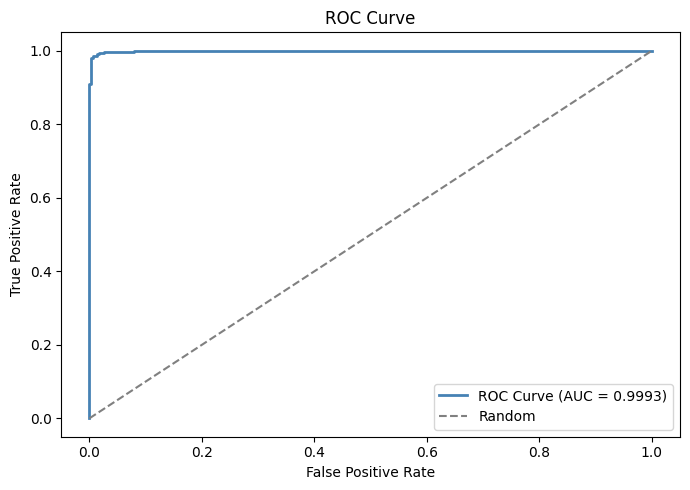

AUC Score: 0.9993


In [9]:
fpr, tpr, _ = roc_curve(y_true, y_pred_prob)
roc_auc     = auc(fpr, tpr)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='steelblue', lw=2,
         label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.tight_layout()
plt.savefig("../outputs/plots/roc_curve.png")
plt.show()
print(f"AUC Score: {roc_auc:.4f}")


Wrong guess: 9 รูป



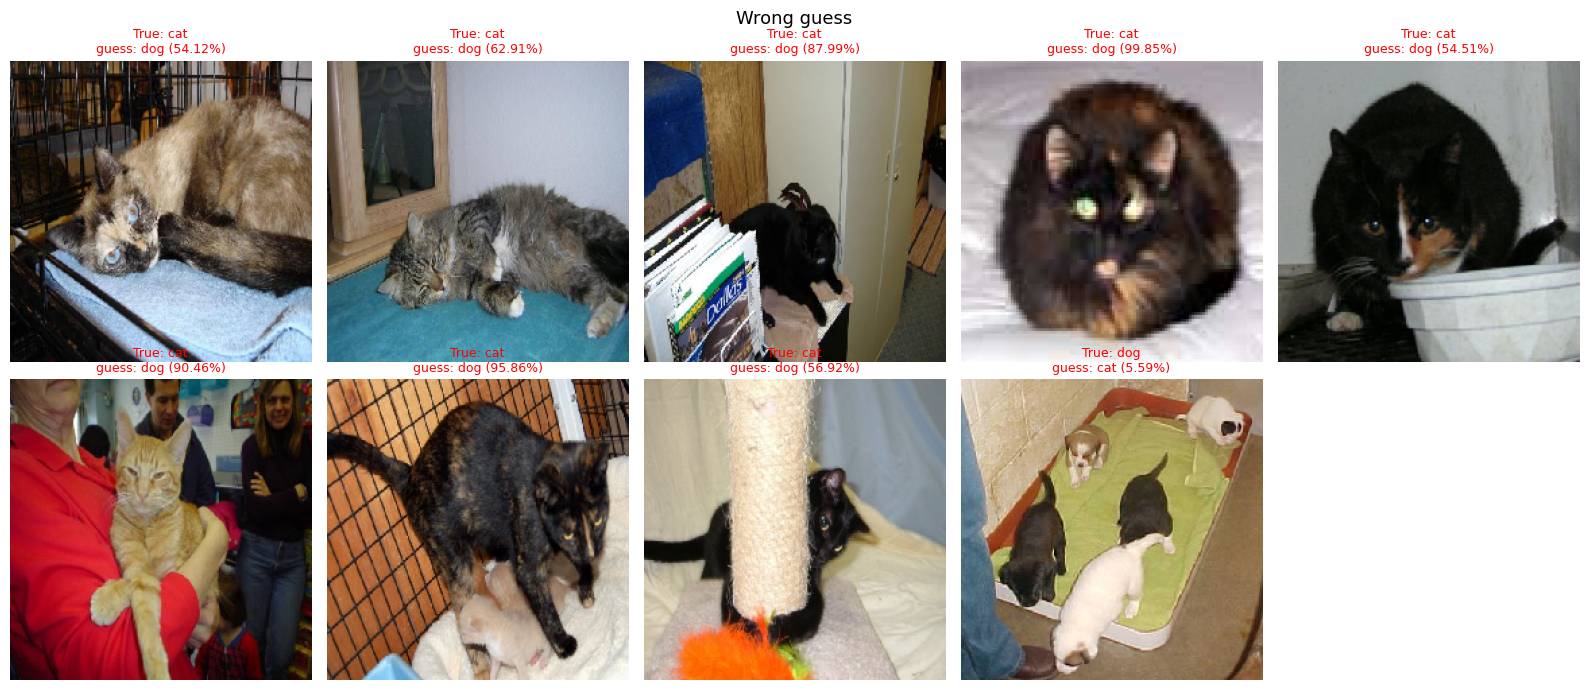

In [10]:
wrong_idx   = np.where(y_pred != y_true)[0]
image_paths = test_gen.filepaths

print(f"\nWrong guess: {len(wrong_idx)} รูป\n")

show_n = min(10, len(wrong_idx))
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
axes = axes.flatten()

for i, idx in enumerate(wrong_idx[:show_n]):
    img = tf.keras.utils.load_img(image_paths[idx], target_size=(224, 224))
    axes[i].imshow(img)
    actual    = class_names[y_true[idx]]
    predicted = class_names[y_pred[idx]]
    conf      = y_pred_prob[idx][0]
    axes[i].set_title(f"True: {actual}\nguess: {predicted} ({conf:.2%})",
                      color='red', fontsize=9)
    axes[i].axis('off')

for j in range(show_n, len(axes)):
    axes[j].axis('off')

plt.suptitle("Wrong guess", fontsize=13)
plt.tight_layout()
plt.savefig("../outputs/plots/wrong_predictions.png")
plt.show()

In [11]:
loss, acc = model.evaluate(test_gen, verbose=0)

print("=" * 40)
print("Test Set")
print("=" * 40)
print(f"  Accuracy  : {acc:.2%}")
print(f"  Loss      : {loss:.4f}")
print(f"  AUC Score : {roc_auc:.4f}")
print(f"  ทายผิด    : {len(wrong_idx)} / {len(y_true)} รูป")
print("=" * 40)

Test Set
  Accuracy  : 98.50%
  Loss      : 0.0439
  AUC Score : 0.9993
  ทายผิด    : 9 / 600 รูป
